<a href="https://colab.research.google.com/github/shreyasjoshinie/4NI25CS187_DAV_LAB/blob/main/4NI25CS187_EXP_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
df= pd.read_csv('House_Price_dataset.csv')
# Load dataset and select features
df = df[df['purpose'] == 'For Sale']
df = df[['price', 'bedrooms', 'baths', 'Area Size']].dropna()



In [ ]:
# Clean data: remove zero values and extreme outliers
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

In [ ]:
df=df.sample(n=100,random_state=42).reset_index(drop=True)
X=df[["price","bedrooms","baths","Area Size"]]
X_scaled=StandardScaler().fit_transform(X)

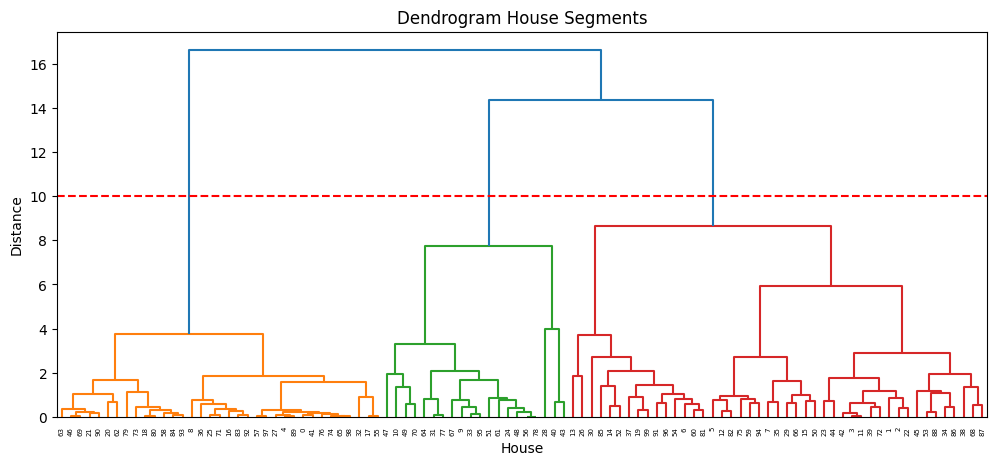

In [ ]:
linked = linkage(X_scaled, 'ward')
plt.figure(figsize=(12,5))
dendrogram(linked)
plt.title('Dendrogram House Segments')
plt.xlabel('House')
plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

In [ ]:
hc = AgglomerativeClustering(n_clusters=3,linkage='ward')
df["HC_Cluster"] = hc.fit_predict(X_scaled)

In [ ]:
print(df["HC_Cluster"].value_counts())
print(df.groupby("HC_Cluster").mean().round(2))

HC_Cluster
0    45
1    35
2    20
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0           19971111.11      4.33   4.62       8.77
1            6272142.86      2.34   2.29       3.68
2           51225000.00      5.20   5.55       1.27


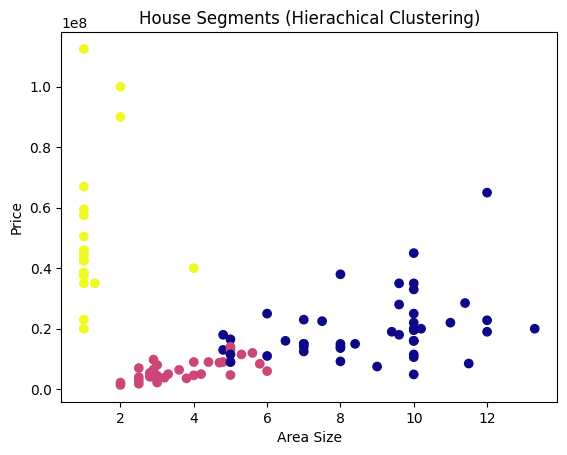

In [ ]:
plt.scatter(df['Area Size'],df['price'],c=df['HC_Cluster'],cmap='plasma')
plt.xlabel('Area Size')
plt.ylabel('Price')
plt.title('House Segments (Hierachical Clustering)')
plt.show()